# 05 Customer value and recommendations

This notebook puts reais on the findings so far and turns them into a short list of actions.

1. Customer value: what each customer has spent, and what they are expected to spend in the next 180 days given their chance of returning.
2. The size of the prize: what Olist gains if the repeat rate rises, under clearly labelled assumptions.
3. The delivery problem in reviews, in numbers.
4. A playbook by segment, a break-even test for a second-order voucher, and a one-page summary.

Outputs: `data/processed/clv_scores.csv` and `reports/figures/05_executive_summary.png`

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import olist as ol

ol.set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

cust = ol.load_customers()
orders = ol.load_orders()
scores = pd.read_csv(ol.PROCESSED / "repeat_scores.csv")
rfm = pd.read_csv(ol.PROCESSED / "rfm_segments.csv")
cust = cust.merge(scores[["customer_unique_id", "p_repeat_180d", "return_tier"]], on="customer_unique_id")
cust = cust.merge(rfm[["customer_unique_id", "segment"]], on="customer_unique_id")
done = orders[orders["completed"] == 1].copy()
metrics = json.loads((ol.PROCESSED / "model_metrics.json").read_text())

## 1. Customer value

Two parts:

1. Historical value: everything the customer has spent so far (items plus freight).
2. Expected 180-day repeat value: the model's probability that the customer returns within 180 days, times what a returning customer typically spends in that window.

Why 180 days and not a lifetime? Olist's data covers 20 months and almost nobody buys a third time, so any lifetime figure would be a guess stacked on a guess. A 180-day horizon stays inside what the data can support.

In [2]:
fp = cust.set_index("customer_unique_id")["first_purchase"]
done["since_first"] = (done["purchase_ts"] - done["customer_unique_id"].map(fp)).dt.total_seconds() / 86400
later_day = done["purchase_ts"].dt.normalize() > done["customer_unique_id"].map(fp.dt.normalize())
labelled = cust.loc[cust["repeat_180d_observed"] == 1, "customer_unique_id"]
repeat_spend = (done[later_day & (done["since_first"] <= 180) & done["customer_unique_id"].isin(labelled)]
                .groupby("customer_unique_id")["order_value"].sum())
REPEAT_VALUE = repeat_spend.mean()
print(f"Customers who returned within 180 days: {len(repeat_spend):,}")
print(f"Their spend after the first day, within 180 days: mean {ol.brl(REPEAT_VALUE)}, median {ol.brl(repeat_spend.median())}")

cust["expected_repeat_value_180d"] = cust["p_repeat_180d"] * REPEAT_VALUE
cust["customer_value"] = cust["total_spend"] + cust["expected_repeat_value_180d"]
cust[["total_spend", "expected_repeat_value_180d", "customer_value"]].describe(percentiles=[0.5, 0.9]).T

Customers who returned within 180 days: 1,135
Their spend after the first day, within 180 days: mean R$163, median R$113


,count,mean,std,min,50%,90%,max
total_spend,"94,703.00",165.61,226.81,9.59,107.88,318.69,"13,664.08"
expected_repeat_value_180d,"94,703.00",3.38,1.54,0.00,3.25,4.43,45.06
customer_value,"94,703.00",168.99,226.86,17.50,111.29,322.07,"13,669.32"


The expected repeat value is small next to what customers have already spent: an average of a few reais per customer against about R$166 historical spend. That is not a modelling problem, it is the business: with a 2% return rate, the future is worth little unless the rate changes.

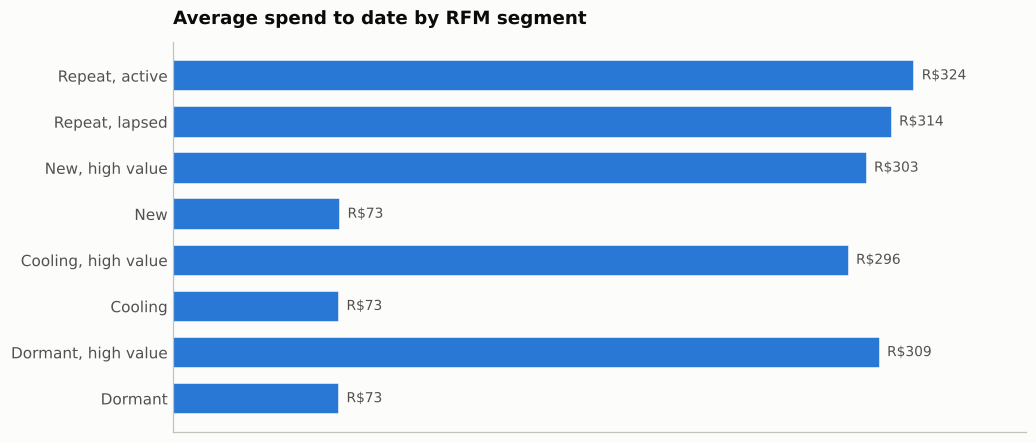

,customers,historical,expected_180d,p_repeat
segment,,,,
"Repeat, active","1,465",R$324,R$4.57,2.80%
"Repeat, lapsed",588,R$314,R$6.08,3.72%
"New, high value","14,707",R$303,R$3.45,2.12%
New,"22,091",R$73,R$3.65,2.24%
"Cooling, high value","14,447",R$296,R$3.24,1.99%
Cooling,"22,677",R$73,R$3.11,1.91%
"Dormant, high value","7,053",R$309,R$3.34,2.05%
Dormant,"11,675",R$73,R$3.22,1.98%


In [3]:
seg = cust.groupby("segment").agg(customers=("customer_unique_id", "size"), historical=("total_spend", "mean"),
                                  expected_180d=("expected_repeat_value_180d", "mean"),
                                  p_repeat=("p_repeat_180d", "mean"))
seg = seg.loc[[s for s in ["Repeat, active", "Repeat, lapsed", "New, high value", "New", "Cooling, high value",
                           "Cooling", "Dormant, high value", "Dormant"] if s in seg.index]]

fig, ax = plt.subplots(figsize=(10, 4.6))
ol.hbar(ax, seg.index, seg["historical"], fmt=ol.brl)
ax.set_xticks([])
ax.set_title("Average spend to date by RFM segment")
ol.save(fig, "05_value_by_segment")
plt.show()

seg.style.format({"customers": "{:,}", "historical": ol.brl, "expected_180d": "R${:,.2f}", "p_repeat": "{:.2%}"})

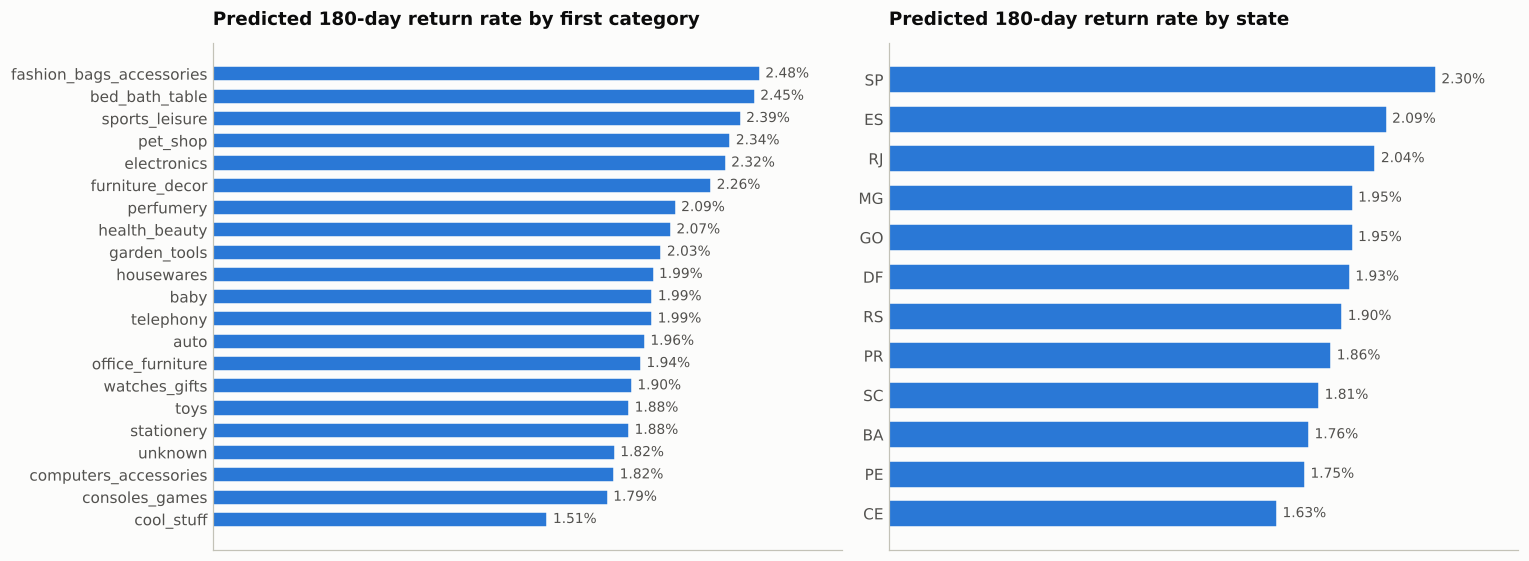

In [4]:
by_cat = cust.groupby("first_lead_category").agg(customers=("customer_unique_id", "size"),
                                                 historical=("total_spend", "mean"),
                                                 p_repeat=("p_repeat_180d", "mean"))
by_cat = by_cat[by_cat["customers"] >= 1000].sort_values("p_repeat", ascending=False)
by_state = cust.groupby("customer_state").agg(customers=("customer_unique_id", "size"),
                                              historical=("total_spend", "mean"),
                                              p_repeat=("p_repeat_180d", "mean"))
by_state = by_state[by_state["customers"] >= 1000].sort_values("p_repeat", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
ol.hbar(axes[0], by_cat.index, by_cat["p_repeat"], fmt=lambda v: f"{v:.2%}")
axes[0].set_xticks([])
axes[0].set_title("Predicted 180-day return rate by first category")
ol.hbar(axes[1], by_state.index, by_state["p_repeat"], fmt=lambda v: f"{v:.2%}")
axes[1].set_xticks([])
axes[1].set_title("Predicted 180-day return rate by state")
fig.tight_layout()
ol.save(fig, "05_return_by_category_state")
plt.show()

## 2. The size of the prize

How much would a higher repeat rate be worth? The calculation:

extra GMV a year = new customers a year x rise in 180-day repeat rate x spend per returning customer

Inputs from the data: about 6,460 new customers a month in 2018 (77,500 a year at that pace) and R$163 spend per returning customer within 180 days. The repeat rates are scenarios, not forecasts.

In [5]:
new_per_month = cust[cust["first_purchase"] >= "2018-01-01"].groupby(
    cust["first_purchase"].dt.to_period("M")).size().mean()
NEW_PER_YEAR = new_per_month * 12
base_rate = cust.loc[cust["repeat_180d_observed"] == 1, "repeat_180d"].mean()
annual_gmv_2018 = done.loc[done["purchase_ts"] >= "2018-01-01", "order_value"].sum() / 8 * 12

scen = pd.DataFrame({"repeat_rate": [base_rate, 0.03, 0.05, 0.10]},
                    index=["today", "3%", "5%", "10%"])
scen["extra_returners"] = (scen["repeat_rate"] - base_rate) * NEW_PER_YEAR
scen["extra_gmv"] = scen["extra_returners"] * REPEAT_VALUE
scen["share_of_annual_gmv"] = scen["extra_gmv"] / annual_gmv_2018
print(f"New customers per month in 2018: {new_per_month:,.0f}; annual GMV at the 2018 pace: {ol.brl(annual_gmv_2018)}")
scen.style.format({"repeat_rate": "{:.1%}", "extra_returners": "{:,.0f}", "extra_gmv": ol.brl,
                   "share_of_annual_gmv": "{:.1%}"})

New customers per month in 2018: 6,459; annual GMV at the 2018 pace: R$12.9M


,repeat_rate,extra_returners,extra_gmv,share_of_annual_gmv
today,2.0%,0,R$0,0.0%
3%,3.0%,790,R$128.8k,1.0%
5%,5.0%,"2,340",R$381.8k,3.0%
10%,10.0%,"6,215",R$1.0M,7.9%


The honest reading: moving the repeat rate from 2% to 3% is worth about R$129,000 a year, about 1% of GMV. Even 10%, five times today's rate, adds about 8%. Retention at Olist is a slow, compounding gain, not a quick win, and the spend on it has to be sized to match. Every reais of incentive must be tested against those modest numbers.

## 3. Late delivery and bad reviews

Notebook 03 found that late delivery has only a small, uncertain effect on repeat buying. Its effect on reviews is large and certain, and reviews are how Olist's shops are rated on the marketplaces. This section counts how many bad reviews late parcels cause.

In [6]:
dl = done[done["delivered_ts"].notna() & done["review_score"].notna()].copy()
dl["bad"] = dl["review_score"] <= 2
on_time_bad_rate = dl.loc[dl["is_late"] == 0, "bad"].mean()
late = dl[dl["is_late"] == 1]
excess = late["bad"].sum() - len(late) * on_time_bad_rate

late_by_state = dl.groupby("customer_state").agg(orders=("order_id", "size"), late_rate=("is_late", "mean"))
late_by_state = late_by_state[late_by_state["orders"] >= 1000].sort_values("late_rate", ascending=False)

print(f"Delivered and reviewed orders: {len(dl):,}; late: {len(late):,} ({len(late) / len(dl):.1%})")
print(f"Bad-review rate: on time {on_time_bad_rate:.1%}, late {late['bad'].mean():.1%}")
print(f"Bad reviews caused by lateness (above the on-time rate): {excess:,.0f}, "
      f"or {excess / dl['bad'].sum():.0%} of all bad reviews")
late_by_state.head(8).style.format({"orders": "{:,}", "late_rate": "{:.1%}"})

Delivered and reviewed orders: 95,560; late: 7,658 (8.0%)
Bad-review rate: on time 9.2%, late 54.1%
Bad reviews caused by lateness (above the on-time rate): 3,435, or 28% of all bad reviews


,orders,late_rate
customer_state,,
CE,"1,267",15.3%
BA,"3,226",13.7%
RJ,"12,172",13.3%
ES,"1,966",11.9%
PE,"1,573",10.7%
SC,"3,510",9.7%
GO,"1,939",8.0%
DF,"2,064",7.1%


## 4. Playbook

| Segment or group | Customers | What to do | Why |
|---|---|---|---|
| New, high value and New (bought in the last 6 months), High return tier | top 10% of scores | A second-order offer 3 to 6 weeks after delivery, in the same category | The only one-time buyers with a real chance of returning; out of time, the model's top 10% returned at about 1.8 times the average rate |
| First order in bed, bath and table, furniture and decor, sports and leisure, fashion bags | about 1 in 4 customers | Replenishment and "complete the set" emails | These categories return at 2.4% to 3.2%, against about 1% for gadgets and car parts |
| Any order more than 3 days late | about 5% of orders | Automatic apology and a small voucher as soon as the parcel misses its date | 60% to 76% of these customers leave 1 or 2 stars; a quick gesture protects the shop's rating |
| Rio de Janeiro and the north-east (RJ, BA, CE, PE, ES) | about a fifth of customers | Fix delivery promises first: carriers, seller location, realistic dates | Late rates of 11% to 15% against about 6% in SP |
| Cooling and Dormant | about 59% of customers | Low-cost newsletter only; suppress after 12 months with no purchase | Return odds fall away after a few months; paid incentives here won't pay back |
| Repeat customers | about 2% of customers, 4% of revenue | Keep them: early access to Black Friday deals, ask for referrals | Small group, but the proof that a returning base can exist |

The playbook leans on email and timing rather than discounts, because section 2 shows the prize is too small to fund broad incentives.

## 5. Break-even test for a second-order voucher

Suppose Olist sends the High tier of new customers a R$15 voucher for a second order within 90 days. Two numbers decide whether it pays: how many extra customers it brings back, and how much of a returning customer's spend Olist keeps as margin. The data contains neither: Olist's commission and costs are not public, and no voucher experiment was run. So instead of guessing a return, the calculation finds the break-even point for a range of margins.

Assumptions, all labelled:

1. Voucher R$15, paid only when redeemed. Everyone in the tier who would have returned anyway redeems it too, which is the main cost.
2. Baseline return rate of the High tier: the model's out-of-time test rate for its top 10% (notebook 04), not the flattering in-sample rate.
3. Margin on a returning customer's spend: 10%, 20% or 30% (scenarios).

In [7]:
VOUCHER = 15.0
targeted_per_year = 0.10 * NEW_PER_YEAR
p_high = metrics["top10_precision"]

rows = []
for margin in (0.10, 0.20, 0.30):
    gain_per_extra = REPEAT_VALUE * margin - VOUCHER
    if gain_per_extra <= 0:
        rows.append({"margin": margin, "profit per extra returner": gain_per_extra, "break-even uplift": np.nan,
                     "break-even return rate": np.nan})
        continue
    # extra returners x (margin x value - voucher) must cover the voucher paid to those who would have returned anyway
    extra_needed = p_high * VOUCHER / gain_per_extra
    rows.append({"margin": margin, "profit per extra returner": gain_per_extra,
                 "break-even uplift": extra_needed, "break-even return rate": p_high + extra_needed})
be = pd.DataFrame(rows).set_index("margin")
print(f"High tier: {targeted_per_year:,.0f} new customers a year; their return rate without a voucher about {p_high:.2%}")
be.style.format({"profit per extra returner": "R${:,.2f}", "break-even uplift": "{:+.2%}",
                 "break-even return rate": "{:.2%}"}).format_index("{:.0%}")

High tier: 7,751 new customers a year; their return rate without a voucher about 3.20%


,profit per extra returner,break-even uplift,break-even return rate
margin,,,
10%,R$1.32,+36.35%,39.54%
20%,R$17.64,+2.72%,5.92%
30%,R$33.96,+1.41%,4.61%


At a 10% margin the voucher leaves R$1.32 per extra returner, so it would need to lift the return rate by 36 points to cover the vouchers paid to people who would have come back anyway. It won't pay. At 20% it needs the High tier's return rate to go from 3.2% to 5.9%, and at 30% to 4.6%: between half again and nearly double. That is a test worth running on a random half of the High tier with the other half held out, not a programme to roll out on faith.

## 6. One-page summary

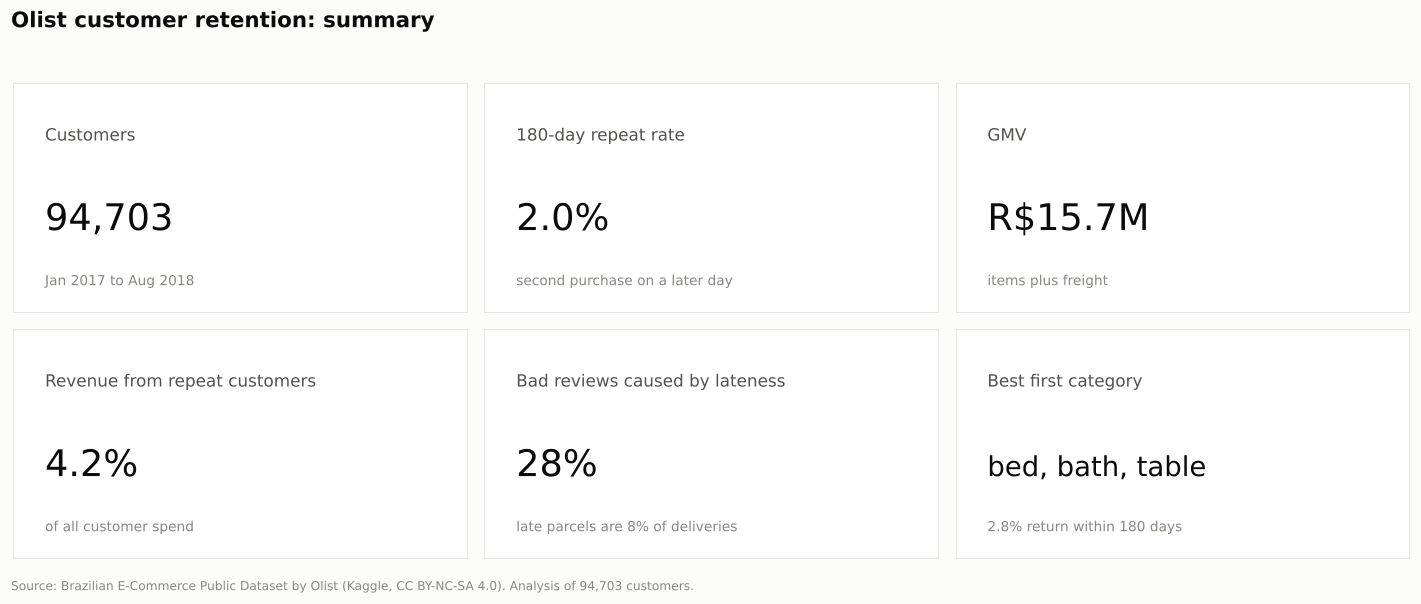

In [8]:
repeat_share_rev = cust.loc[cust["repeat_ever"] == 1, "total_spend"].sum() / cust["total_spend"].sum()
tiles = [
    ("Customers", f"{len(cust):,}", "Jan 2017 to Aug 2018"),
    ("180-day repeat rate", f"{base_rate:.1%}", "second purchase on a later day"),
    ("GMV", ol.brl(done["order_value"].sum()), "items plus freight"),
    ("Revenue from repeat customers", f"{repeat_share_rev:.1%}", "of all customer spend"),
    ("Bad reviews caused by lateness", f"{excess / dl['bad'].sum():.0%}", "late parcels are 8% of deliveries"),
    ("Best first category", "bed, bath, table", "2.8% return within 180 days"),
]
fig, axes = plt.subplots(2, 3, figsize=(13, 5.4))
for ax, (label, value, note) in zip(axes.flat, tiles):
    ax.set_axis_off()
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, facecolor="white", edgecolor=ol.GRID))
    ax.text(0.07, 0.75, label, fontsize=11, color=ol.INK_2, transform=ax.transAxes)
    ax.text(0.07, 0.36, value, fontsize=24 if len(value) < 12 else 18, color=ol.INK, transform=ax.transAxes)
    ax.text(0.07, 0.12, note, fontsize=9, color=ol.MUTED, transform=ax.transAxes)
fig.suptitle("Olist customer retention: summary", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.text(0.01, 0.005, "Source: Brazilian E-Commerce Public Dataset by Olist (Kaggle, CC BY-NC-SA 4.0). "
         "Analysis of 94,703 customers.", fontsize=8, color=ol.MUTED)
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
ol.save(fig, "05_executive_summary")
plt.show()

In [9]:
out = cust[["customer_unique_id", "customer_state", "segment", "return_tier", "total_spend", "p_repeat_180d",
            "expected_repeat_value_180d", "customer_value"]]
out.to_csv(ol.PROCESSED / "clv_scores.csv", index=False)
print(f"Wrote {len(out):,} rows to data/processed/clv_scores.csv")

Wrote 94,703 rows to data/processed/clv_scores.csv


## Findings

1. An Olist customer is worth about R$166 in spend to date, and the expected value of a repeat purchase in the next 180 days adds only about R$3. With a 2% return rate, customer value is the first order.
2. Raising the 180-day repeat rate from 2% to 3% would add about R$129,000 of GMV a year (1%); reaching 10% would add about R$1.0M (8%). Retention is worth working on, but only with cheap tools: email, timing and category targeting, not blanket discounts.
3. A R$15 second-order voucher for the model's top 10% only pays if Olist's margin is 20% or more and the voucher lifts that group's return rate from 3.2% to between 4.6% and 5.9%. That is a hypothesis for a controlled test, not a plan.
4. Late delivery causes about 3,400 bad reviews over the period, 28% of all 1 and 2-star reviews, counting only those above the on-time rate. The worst late rates are in Ceará, Bahia and Rio de Janeiro (13% to 15%). Fixing delivery promises there protects the shops' marketplace ratings, which is the case for it; a big rise in repeat buying is not.
5. The order of work: fix late deliveries in RJ and the north-east, set up a second-order email for recent customers in the home, sports and fashion-bag categories, and run one controlled voucher test on the High tier.